# Noise-Aware Microscopy Denoising: AI4Life 2D Nuclei (Kaggle, resumable)
**Experiments (one cell each):** E1 noisy input and E2 Gaussian/median (same cell), λ sweep, E3 U-Net, E4 U-Net + edge loss, E5 noise-aware U-Net (noise estimate + FiLM), E6 both ideas, E7 standalone Swin denoiser (no U-Net), E8 noise-aware Swin + edge loss. Every experiment is run with **3-fold cross-validation**.

**Kaggle setup:** (1) add your dataset (Add Input), (2) Settings → Accelerator: **GPU**, (3) Settings → Internet: **On** (only needed if `timm` must be upgraded), (4) run the cells in order. Cells of finished experiments can be re-run safely; they skip finished work.

**Resume / checkpoints** (folder `/kaggle/working/ckpt`): model + optimizer + scheduler are saved after **every epoch**; final weights and `results.csv` after **every finished run**. If a cell is interrupted or the session dies, re-run the same cell: finished runs are skipped and the unfinished run continues from its last epoch.
- **Long runs:** *Save Version → Save & Run All (Commit)*. The notebook pauses itself after `STOP_AFTER_H` hours (default 11, below Kaggle's 12 h limit). To continue: open the notebook, *Add Input → Your Work / Notebook Output →* choose the previous version, run again; the setup cell restores `ckpt` automatically.
- **Interactive session:** run the last cell to create `ckpt_backup.zip`, and download it before the session ends.

**Test sets:** 3-fold CV on `small_images` (256x256): each fold holds out one third as the *in-domain* test set; the rest is split 90/10 into train/validation (validation picks the best checkpoint). The *hold-out condition* is `large_images` (1024x1024), never seen in training, tested with the model of every fold. Tables show mean and std over folds (and seeds).

**About Swin:** the Swin model is separate from the U-Net (SwinIR-style: conv stem, shifted-window Swin blocks, residual output). It regresses the clean image; it is not a segmentation network.

In [2]:
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError
def ok(p, v=0):
    try: return int(version(p).split('.')[0]) >= v
    except PackageNotFoundError: return False
if not (ok('timm', 1) and ok('tifffile')):   # Kaggle's timm can be old; the Swin blocks need timm>=1.0 (turn Internet ON in notebook settings)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'timm', 'tifffile'])
import os; os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'   # Mac: let unsupported ops fall back to CPU (must be set before importing torch)
import time, shutil, pickle, json, zipfile, random, numpy as np, pandas as pd, matplotlib.pyplot as plt, tifffile as tf, cv2, torch, torch.nn as nn, torch.nn.functional as F, timm
from pathlib import Path
from skimage.metrics import structural_similarity as ssim_fn
from skimage.filters import threshold_otsu

# ---------------- config ----------------
QUICK = False                       # True = tiny smoke test (few images, 1 epoch, 1 seed)
def find_data():   # works for an extracted Kaggle dataset, a raw .zip dataset, or a local folder/zip
    roots = [Path('/kaggle/input'), Path('.')]
    for r in roots:
        for p in r.rglob('small_images'):
            if '__MACOSX' not in p.parts and (p / 'gt').exists(): return p.parent
    for r in roots:
        for z in r.rglob('*.zip'):
            zipfile.ZipFile(z).extractall('data'); return find_data()
    raise FileNotFoundError('Add your dataset (folders large_images/ and small_images/ or the zip) to the notebook')
DATA = find_data(); print('data at', DATA)
SEEDS, EPOCHS, BS = [0], 30, 16        # seeds per fold; runs per experiment = 3 folds x len(SEEDS)
STOP_AFTER_H = 11                   # pause cleanly (all saved) after this many hours; Kaggle's session limit is 12 h
LAMBDAS = [0.05, 0.1, 0.2]          # edge-loss weights to tune on validation
N_S = N_L = None
if QUICK: SEEDS, EPOCHS, BS, LAMBDAS, N_S, N_L = [0], 1, 4, [0.1], 30, 2
DEV = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'; AMP = DEV == 'cuda'   # mixed precision only on CUDA

# ---------------- checkpoints / resume ----------------
WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('.'); CK = WORK / 'ckpt'; CK.mkdir(parents=True, exist_ok=True); T0 = time.time()
class Paused(Exception): pass
def save(obj, p): torch.save(obj, f'{p}.tmp'); os.replace(f'{p}.tmp', p)   # atomic write: a kill mid-save cannot corrupt a checkpoint
if not any(CK.iterdir()):   # fresh session: restore checkpoints of a previous version (Add Input -> Notebook Output)
    for p in Path('/kaggle/input').rglob('ckpt'):
        if p.is_dir() and any(p.iterdir()): shutil.copytree(p, CK, dirs_exist_ok=True); print('restored checkpoints from', p); break
print('device:', DEV, '| checkpoint folder:', CK, '| files in it:', len(list(CK.iterdir())))

data at /kaggle/input/datasets/abinashmallick07/cell-images
device: cuda | checkpoint folder: /kaggle/working/ckpt | files in it: 0


## 1. Exploratory data analysis

In [9]:
def load(dom, n=None):
    fs = sorted(p.name for p in (DATA / dom / 'gt').glob('*.tif') if not p.name.startswith('._'))[:n]
    rd = lambda k: np.stack([tf.imread(DATA / dom / k / f) for f in fs]).astype(np.float32)
    assert all((DATA / dom / 'noisy' / f).exists() for f in fs), 'unpaired files'
    return fs, rd('noisy'), rd('gt')

S = {'small': load('small_images', N_S), 'large': load('large_images', N_L)}

# helpers used in EDA and later
def norm(a):  # per-image percentile normalisation to [0,1] (noisy and GT have very different raw scales)
    out = []
    for x in a:
        lo, hi = np.percentile(x, [1, 99.8]); out.append(np.clip((x - lo) / (hi - lo + 1e-8), 0, 1))
    return np.stack(out).astype(np.float32)

K = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
def sigma(a):  # Immerkaer noise-std estimate from the high-pass (left-over) residual of each image
    return np.array([np.abs(cv2.filter2D(x, -1, K)).mean() for x in a]) * np.sqrt(np.pi / 2) / 6

rows = []
for d, (fs, X, G) in S.items():
    rows.append(dict(domain=d, n_pairs=len(fs), shape=X.shape[1:], dtype='uint16', noisy_mean=X.mean(), gt_mean=G.mean(),
                     gt_to_noisy_ratio=G.mean() / X.mean(), noisy_max=X.max(), gt_max=G.max(),
                     gt_saturated_pct=100 * (G >= 65535).mean(), noisy_zero_pct=100 * (X == 0).mean(),
                     raw_corr=np.mean([np.corrcoef(x.ravel(), g.ravel())[0, 1] for x, g in zip(X, G)])))
pd.DataFrame(rows).set_index('domain').round(3).T

domain,small,large
n_pairs,2457,20
shape,"(256, 256)","(1024, 1024)"
dtype,uint16,uint16
noisy_mean,10.381,614.75
gt_mean,291.240997,5855.463867
gt_to_noisy_ratio,28.056,9.525
noisy_max,190.0,32279.0
gt_max,4095.0,65535.0
gt_saturated_pct,0.0,0.005
noisy_zero_pct,28.832,0.024


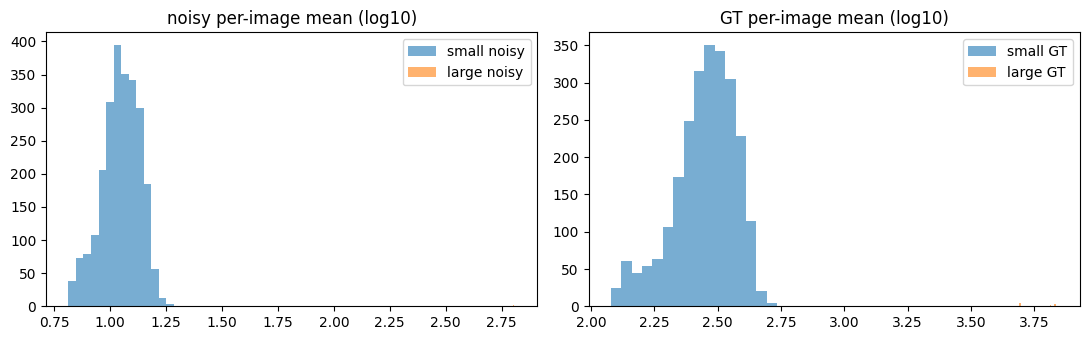

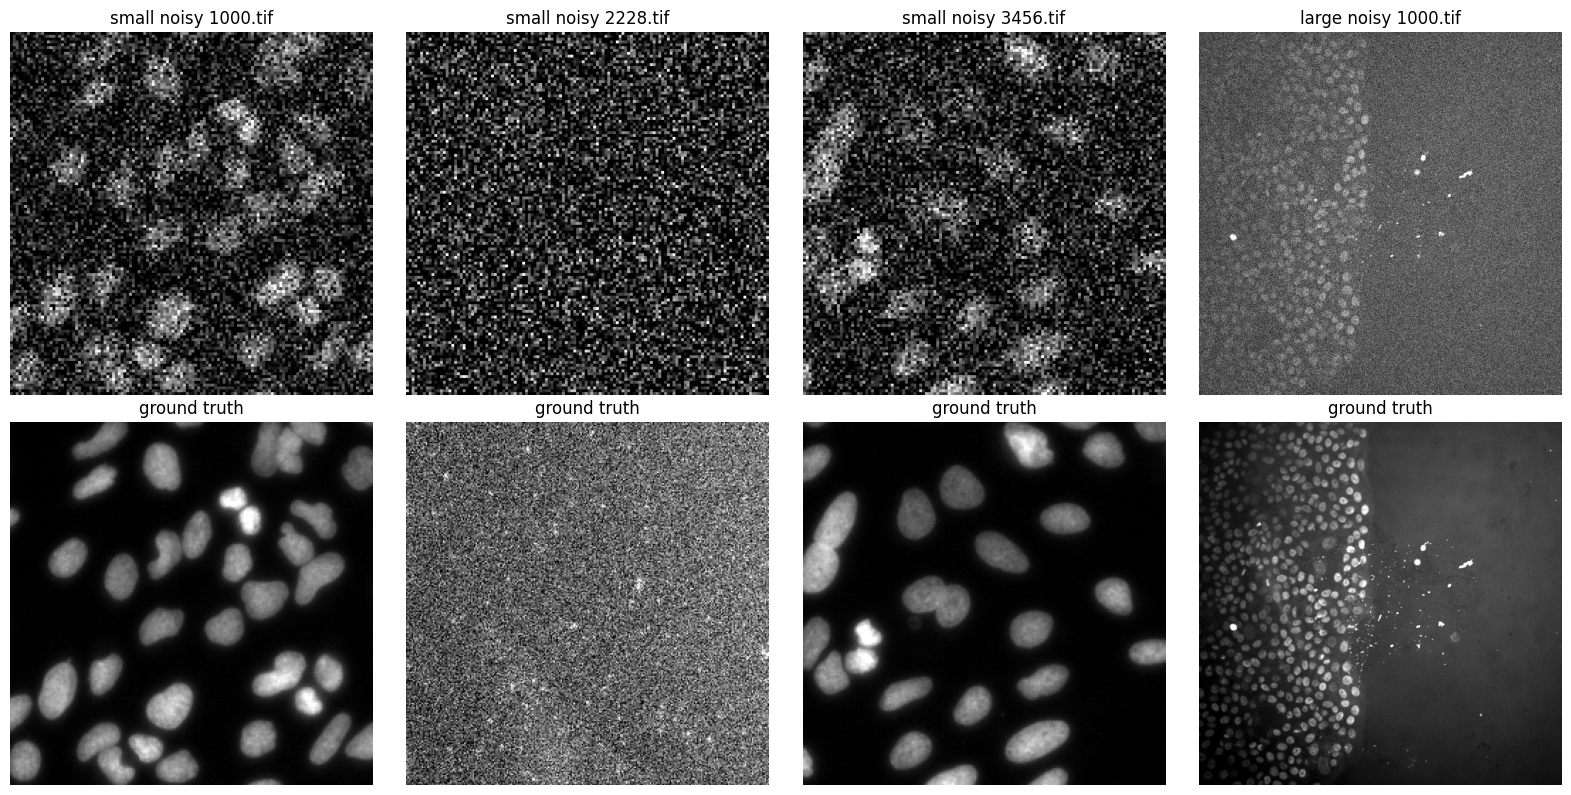

In [10]:
# per-image mean intensity (raw) and visual samples
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for d, (fs, X, G) in S.items():
    ax[0].hist(np.log10(X.mean((1, 2)) + 1), 30, alpha=.6, label=f'{d} noisy')
    ax[1].hist(np.log10(G.mean((1, 2)) + 1), 30, alpha=.6, label=f'{d} GT')
for a, t in zip(ax, ['noisy per-image mean', 'GT per-image mean']): a.set_title(t + ' (log10)'); a.legend()
plt.tight_layout(); plt.show()

picks = [('small', 0), ('small', len(S['small'][0]) // 2), ('small', -1), ('large', 0)]
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j, (d, i) in enumerate(picks):
    fs, X, G = S[d]; ax[0, j].imshow(norm(X[i:i+1] if i != -1 else X[-1:])[0], cmap='gray'); ax[0, j].set_title(f'{d} noisy {fs[i]}')
    ax[1, j].imshow(norm(G[i:i+1] if i != -1 else G[-1:])[0], cmap='gray'); ax[1, j].set_title('ground truth')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

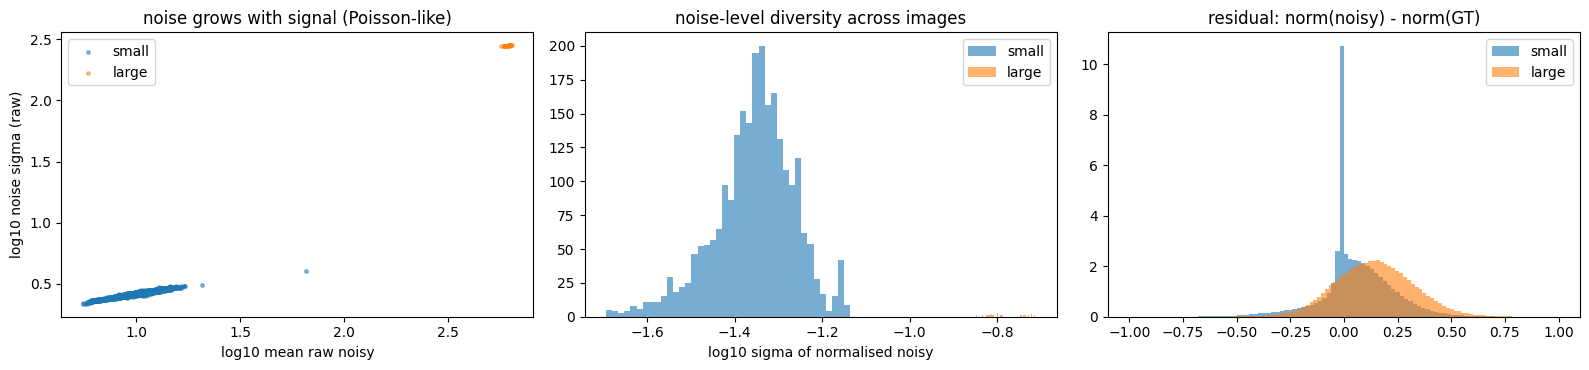

          min     25%     50%     75%     max
small  0.0202  0.0395  0.0450  0.0505  0.0731
large  0.1416  0.1533  0.1585  0.1830  0.1936


In [11]:
# noise analysis: is noise signal-dependent? how much do noise levels vary?
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); q = []
for d, (fs, X, G) in S.items():
    N, Yn = norm(X), norm(G); sr, sn = sigma(X), sigma(N)
    ax[0].scatter(np.log10(X.mean((1, 2)) + 1e-6), np.log10(sr + 1e-6), s=6, alpha=.5, label=d)
    ax[1].hist(np.log10(sn + 1e-6), 40, alpha=.6, label=d)
    ax[2].hist((N - Yn).ravel()[::50], 100, alpha=.6, label=d, density=True)
    q.append(pd.Series(sn, name=d).describe()[['min', '25%', '50%', '75%', 'max']])
ax[0].set(xlabel='log10 mean raw noisy', ylabel='log10 noise sigma (raw)', title='noise grows with signal (Poisson-like)')
ax[1].set(xlabel='log10 sigma of normalised noisy', title='noise-level diversity across images')
ax[2].set(title='residual: norm(noisy) - norm(GT)')
for a in ax: a.legend()
plt.tight_layout(); plt.show(); print(pd.DataFrame(q).round(4))

**EDA take-aways (what drives the design):**
- Noisy images are ~10x (large) to ~25x (small) *dimmer* than GT and weakly correlated with it in raw units, so images are **percentile-normalised per image** (noisy and GT separately) and the model works in [0,1].
- `small` (256²) and `large` (1024², very different intensity scale) behave like different imaging conditions, so **train on small, hold out large** is a natural domain-shift test.
- Noise is signal-dependent and its level varies across images; `large` is also **much noisier after normalisation** (estimated sigma ~0.18 vs ~0.05 for `small` in our check). This motivates a **noise-level estimate + FiLM**, and makes the hold-out a hard, out-of-range test.
- Pixel-wise metrics can reward over-smoothing, so we add **edge error** and **Dice** (Otsu masks of output vs GT).

## 2. Preprocessing: normalise, noise-level features, splits, tensors

In [12]:
def feats(raw, nrm):  # 2 scale-free noise features per image (no labels needed): log sigma of normalised image, log relative raw noise
    return np.log(np.stack([sigma(nrm) + 1e-6, sigma(raw) / (raw.mean((1, 2)) + 1e-6) + 1e-6], 1)).astype(np.float32)

fs_s, Xs, Gs = S['small']; fs_l, Xl, Gl = S['large']
Ns, Ys, Nl, Yl = norm(Xs), norm(Gs), norm(Xl), norm(Gl)
Fs, Fl = feats(Xs, Ns), feats(Xl, Nl)
from sklearn.model_selection import KFold
NFOLD = 3; FOLDS = list(KFold(NFOLD, shuffle=True, random_state=42).split(Ns))
T = lambda a: torch.from_numpy(a[:, None]).to(DEV).half()
Z_ = lambda a: torch.from_numpy(np.clip(a, -3, 3)).to(DEV)   # clip bounds the FiLM conditioning so it cannot extrapolate wildly on the hold-out set

def set_fold(k):   # fold k = in-domain test; the rest -> 90% train / 10% validation; large_images = hold-out for every fold
    global Xtr, Ytr, Ztr, Xva, Zva, Yva, TEST, NOISY, va
    trv, te = FOLDS[k]; r = np.random.RandomState(k).permutation(trv); va, tr = r[:len(r) // 10], r[len(r) // 10:]
    mu, sd = Fs[tr].mean(0), Fs[tr].std(0) + 1e-6; z = lambda f: (f - mu) / sd
    Xtr, Ytr, Ztr = T(Ns[tr]), T(Ys[tr]), Z_(z(Fs[tr]))
    Xva, Zva, Yva = T(Ns[va]), Z_(z(Fs[va])), Ys[va]
    TEST = {'in-domain': (T(Ns[te]), Z_(z(Fs[te])), Ys[te]), 'hold-out': (T(Nl), Z_(z(Fl)), Yl)}
    NOISY = {'in-domain': Ns[te], 'hold-out': Nl}
    print(f'fold {k}: train {len(tr)} val {len(va)} test {len(te)} | hold-out noise z-score mean {z(Fl).mean(0).round(1)} (clipped to +-3)')
set_fold(0)
del Xs, Gs, Xl, Gl, S

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)


## 3. Metrics, edge loss, baselines (E1, E2 are run per fold in section 6)

In [13]:
SK = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32)
def sobel(x):
    k = SK.to(x.device)[None, None]; return torch.cat([F.conv2d(x, k, padding=1), F.conv2d(x, k.transpose(2, 3), padding=1)], 1)
edge_l1 = lambda a, b: F.l1_loss(sobel(a), sobel(b))

def metrics(P, G):  # P, G: (N,H,W) in [0,1]; Edge = Sobel L1 (lower is better), Dice on Otsu masks
    out = []
    for p, g in zip(P, G):
        p = np.clip(p, 0, 1).astype(np.float32); mp, mg = p > threshold_otsu(p), g > threshold_otsu(g)
        out.append(dict(PSNR=10 * np.log10(1 / max(((p - g) ** 2).mean(), 1e-10)), SSIM=ssim_fn(p, g, data_range=1),
                        Edge=edge_l1(torch.from_numpy(p)[None, None], torch.from_numpy(g)[None, None]).item(),
                        Dice=2 * (mp & mg).sum() / (mp.sum() + mg.sum() + 1e-8)))
    return pd.DataFrame(out).mean()

gauss = lambda a, s: np.stack([cv2.GaussianBlur(x, (0, 0), s) for x in a])
med = lambda a, k: np.stack([cv2.medianBlur((x * 255).astype(np.uint8), k) / 255. for x in a]).astype(np.float32)
tune = lambda fn, grid: max(grid, key=lambda p: metrics(fn(Ns[va], p), Ys[va]).PSNR)   # tune on the current fold's validation set

res = pd.read_csv(CK / 'results.csv').to_dict('records') if (CK / 'results.csv').exists() else []   # finished runs (resume)
VIS = pickle.load(open(CK / 'vis.pkl', 'rb')) if (CK / 'vis.pkl').exists() else {'in-domain': {}, 'hold-out': {}}   # first 2 images per method (fold 0) for the picture grid
DONE = lambda n, k, sd_: any(r['method'] == n and r['fold'] == k and r['seed'] == sd_ for r in res)
def save_state(): pd.DataFrame(res).to_csv(CK / 'results.csv', index=False); pickle.dump(VIS, open(CK / 'vis.pkl', 'wb'))
def log(name, fold, seed, dom, pred, gt):
    res.append(dict(method=name, fold=fold, seed=seed, domain=dom, **metrics(pred, gt))); VIS[dom].setdefault(name, pred[:2])

def run_baselines(k):   # E1 and E2 on fold k
    if DONE('E2b Median', k, 0): return
    gs, mk = tune(gauss, [.5, 1, 1.5, 2, 3]), tune(med, [3, 5, 7])
    for dom, (_, _, Y) in TEST.items():
        log('E1 Noisy', k, 0, dom, NOISY[dom], Y); log('E2a Gaussian', k, 0, dom, gauss(NOISY[dom], gs), Y); log('E2b Median', k, 0, dom, med(NOISY[dom], mk), Y)
    save_state()

## 4. Models: U-Net and a standalone Swin denoiser (SwinIR-style), both with optional FiLM noise conditioning

In [14]:
class Blk(nn.Module):   # conv-norm-GELU x2, optional FiLM (scale/shift from noise features z), zero-init so it starts as identity
    def __init__(s, i, o, zd=0):
        super().__init__()
        s.c1, s.n1, s.c2, s.n2 = nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.Conv2d(o, o, 3, padding=1), nn.GroupNorm(8, o)
        s.f = nn.Linear(zd, 2 * o) if zd else None
        if s.f: nn.init.zeros_(s.f.weight); nn.init.zeros_(s.f.bias)
    def forward(s, x, z=None):
        x = s.n2(s.c2(F.gelu(s.n1(s.c1(x)))))
        if s.f is not None: g, b = s.f(z)[:, :, None, None].chunk(2, 1); x = x * (1 + g) + b
        return F.gelu(x)

up = lambda h, size=None, sf=2: F.interpolate(h, size=size, scale_factor=None if size else sf, mode='bilinear')

class UNet(nn.Module):
    def __init__(s, zd=0, c=(32, 64, 128, 256)):
        super().__init__()
        s.enc = nn.ModuleList([Blk(i, o, zd) for i, o in zip((1,) + c[:-1], c)])
        s.dec = nn.ModuleList([Blk(c[i + 1] + c[i], c[i], zd) for i in range(len(c) - 1)]); s.out = nn.Conv2d(c[0], 1, 1)
    def forward(s, x, z=None):
        sk, h = [], x
        for i, e in enumerate(s.enc): h = e(h if i == 0 else F.max_pool2d(h, 2), z); sk.append(h)
        for i in range(len(s.dec) - 1, -1, -1): h = s.dec[i](torch.cat([up(h), sk[i]], 1), z)
        return x + s.out(h)

from timm.models.swin_transformer import SwinTransformerBlock as SwinBlk
class SwinDenoiser(nn.Module):   # standalone Swin (SwinIR-style): conv stem -> Swin blocks (window attention, alternating shift) -> residual output. No U-Net.
    def __init__(s, zd=0, dim=48, depths=(2, 2, 2, 2), heads=6, ws=8):
        super().__init__()
        s.head, s.out = nn.Conv2d(1, dim, 3, padding=1), nn.Conv2d(dim, 1, 3, padding=1)
        s.stages = nn.ModuleList([nn.ModuleList([SwinBlk(dim, (256, 256), heads, window_size=ws, shift_size=0 if j % 2 == 0 else ws // 2, dynamic_mask=True)
                                                 for j in range(d)]) for d in depths])
        s.convs = nn.ModuleList([nn.Conv2d(dim, dim, 3, padding=1) for _ in depths])
        s.film = nn.ModuleList([nn.Linear(zd, 2 * dim) for _ in depths]) if zd else None   # FiLM per stage, zero-init
        for f in (s.film or []): nn.init.zeros_(f.weight); nn.init.zeros_(f.bias)
    def forward(s, x, z=None):
        h = s.head(x)
        for i, (blks, cv) in enumerate(zip(s.stages, s.convs)):
            t = h.permute(0, 2, 3, 1)
            for blk in blks: t = blk(t)
            r = cv(t.permute(0, 3, 1, 2))
            if s.film is not None: g, b = s.film[i](z)[:, :, None, None].chunk(2, 1); r = r * (1 + g) + b
            h = h + r
        return x + s.out(h)

@torch.no_grad()
def infer(m, X, Z, film, bs=8):   # 256x256 inputs run directly; 1024x1024 are processed as overlapping 256x256 tiles
    m.eval(); out = []
    for i in range(0, len(X), bs):
        x, z = X[i:i + bs].float(), (Z[i:i + bs] if film else None); H = x.shape[-1]
        if H == 256: p = m(x, z)
        else:
            p, w = torch.zeros_like(x), torch.zeros_like(x)   # overlapping tiles (stride 128), averaged to avoid seams
            for a in range(0, H - 255, 128):
                for b in range(0, H - 255, 128): p[..., a:a + 256, b:b + 256] += m(x[..., a:a + 256, b:b + 256], z); w[..., a:a + 256, b:b + 256] += 1
            p = p / w
        out.append(p.clamp(0, 1).cpu())
    return torch.cat(out)[:, 0].numpy()

## 5. Training function (L1 + λ·edge L1, best-validation checkpoint, resumable) and experiment runner

In [15]:
def aug(x, y):
    k = random.randint(0, 3); x, y = torch.rot90(x, k, (2, 3)), torch.rot90(y, k, (2, 3))
    return (x.flip(3), y.flip(3)) if random.random() < .5 else (x, y)

def train(kind, film, lam, seed, tag, epochs=EPOCHS, pausable=True):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    m = (SwinDenoiser(2 * film) if kind == 'swin' else UNet(2 * film)).to(DEV); lr = 2e-4 if kind == 'swin' else 1e-3
    fin, last = CK / f'{tag}_final.pt', CK / f'{tag}_last.pt'
    if fin.exists(): m.load_state_dict(torch.load(fin, map_location=DEV)); print('loaded finished run', tag); return m.eval()
    opt = torch.optim.AdamW(m.parameters(), lr, weight_decay=1e-4); n = len(Xtr)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * ((n + BS - 1) // BS), pct_start=.1)
    sc, best, ep0 = torch.amp.GradScaler(enabled=AMP), (1e9, None), 0
    if last.exists():   # resume an interrupted run from its last finished epoch
        d = torch.load(last, map_location=DEV, weights_only=False)
        m.load_state_dict(d['m']); opt.load_state_dict(d['o']); sch.load_state_dict(d['s']); sc.load_state_dict(d['g']); best, ep0 = d['best'], d['ep']
        print(f'resumed {tag} at epoch {ep0}/{epochs}')
    for ep in range(ep0, epochs):
        m.train()
        for b in torch.randperm(n, device=DEV).split(BS):
            x, y = aug(Xtr[b].float(), Ytr[b].float())
            if kind == 'swin':   # Swin trains on random 128x128 crops (memory); inference uses full 256x256 / tiles
                i, j = random.randint(0, 128), random.randint(0, 128); x, y = x[..., i:i + 128, j:j + 128], y[..., i:i + 128, j:j + 128]
            with torch.autocast(DEV, enabled=AMP): p = m(x, Ztr[b] if film else None)
            p = p.float(); loss = F.l1_loss(p, y) + (lam * edge_l1(p, y) if lam else 0)
            opt.zero_grad(set_to_none=True); sc.scale(loss).backward(); sc.step(opt); sc.update(); sch.step()
        v = np.abs(infer(m, Xva, Zva, film) - Yva).mean(); print(f'{tag} epoch {ep + 1}/{epochs} val L1 {v:.4f} | elapsed h {(time.time() - T0) / 3600:.2f}')
        if v < best[0]: best = (v, {k: t.detach().clone() for k, t in m.state_dict().items()})
        save(dict(m=m.state_dict(), o=opt.state_dict(), s=sch.state_dict(), g=sc.state_dict(), best=best, ep=ep + 1), last)
        if pausable and ep + 1 < epochs and time.time() - T0 > STOP_AFTER_H * 3600: raise Paused(tag)
    m.load_state_dict(best[1]); save(m.state_dict(), fin); last.unlink(missing_ok=True); return m.eval()

META = CK / 'meta.json'   # stores the chosen lambda
EXPS = {'E3 U-Net': ('unet', 0, 0), 'E4 U-Net+edge': ('unet', 0, 'LAM'), 'E5 NoiseAware U-Net': ('unet', 1, 0),
        'E6 NoiseAware U-Net+edge': ('unet', 1, 'LAM'), 'E7 Swin': ('swin', 0, 0), 'E8 NoiseAware Swin+edge': ('swin', 1, 'LAM')}   # 'LAM' = value from the lambda sweep

def get_lam():
    if not META.exists(): raise RuntimeError('Run the lambda-sweep cell first')
    return json.load(open(META))['LAM']

def run_exp(name):   # one experiment = NFOLD folds x SEEDS; finished runs are skipped, an unfinished run resumes from its last epoch
    kind, film, lam = EXPS[name]; lam = get_lam() if lam == 'LAM' else lam
    if time.time() - T0 > STOP_AFTER_H * 3600: print(name, ': time budget reached, skipped (re-run in a new session)'); return
    try:
        for k in range(NFOLD):
            for sd_ in SEEDS:
                if DONE(name, k, sd_): continue
                set_fold(k); m = train(kind, film, lam, 10 * sd_ + k, f'f{k}_{name.split()[0]}_s{sd_}')
                for dom, (X, Z, Y) in TEST.items(): log(name, k, sd_, dom, infer(m, X, Z, film), Y)
                save_state(); print(name, 'fold', k, 'seed', sd_, 'DONE | elapsed h:', round((time.time() - T0) / 3600, 2)); del m
                if DEV != 'cpu': getattr(torch, DEV).empty_cache()
    except Paused as e: print(f'PAUSED during {e} (time budget reached). Everything is saved: save a version / re-run this cell to continue.')
    print(name, ':', 'finished' if all(DONE(name, k, sd_) for k in range(NFOLD) for sd_ in SEEDS) else 'NOT finished yet (re-run this cell)')

## 6. Experiments (one cell each, 3-fold CV)

### E1 Noisy input and E2 Gaussian / median filters (no training)

In [15]:
for k in range(NFOLD): set_fold(k); run_baselines(k)
print('baselines done for', NFOLD, 'folds')

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)
fold 1: train 1475 val 163 test 819 | hold-out noise z-score mean [6.1 3.6] (clipped to +-3)
fold 2: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)
baselines done for 3 folds


### λ sweep: edge-loss weight, tuned on fold 0's validation set (plain U-Net, seed 0)
Needed before E4, E6 and E8. Resumable: finished sweep runs are reloaded from disk.

In [16]:
if META.exists(): LAM = get_lam(); print('lambda restored from checkpoint:', LAM)
else:
    set_fold(0)
    sweep = {lam: metrics(infer(train('unet', 0, lam, 0, f'sweep_{lam}', pausable=False), Xva, Zva, 0), Yva) for lam in LAMBDAS}
    sweep = pd.DataFrame(sweep).T.round(4); LAM = float(sweep.SSIM.idxmax()); print(sweep); print('-> lambda =', LAM); json.dump({'LAM': LAM}, open(META, 'w'))

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)
sweep_0.05 epoch 1/30 val L1 0.0380 | elapsed h 0.69
sweep_0.05 epoch 2/30 val L1 0.0311 | elapsed h 0.69
sweep_0.05 epoch 3/30 val L1 0.0280 | elapsed h 0.70
sweep_0.05 epoch 4/30 val L1 0.0266 | elapsed h 0.71
sweep_0.05 epoch 5/30 val L1 0.0263 | elapsed h 0.72
sweep_0.05 epoch 6/30 val L1 0.0299 | elapsed h 0.72
sweep_0.05 epoch 7/30 val L1 0.0257 | elapsed h 0.73
sweep_0.05 epoch 8/30 val L1 0.0243 | elapsed h 0.74
sweep_0.05 epoch 9/30 val L1 0.0232 | elapsed h 0.75
sweep_0.05 epoch 10/30 val L1 0.0234 | elapsed h 0.75
sweep_0.05 epoch 11/30 val L1 0.0227 | elapsed h 0.76
sweep_0.05 epoch 12/30 val L1 0.0249 | elapsed h 0.77
sweep_0.05 epoch 13/30 val L1 0.0221 | elapsed h 0.78
sweep_0.05 epoch 14/30 val L1 0.0225 | elapsed h 0.78
sweep_0.05 epoch 15/30 val L1 0.0229 | elapsed h 0.79
sweep_0.05 epoch 16/30 val L1 0.0223 | elapsed h 0.80
sweep_0.05 epoch 17/30 val L1 0.0216 | elapsed h 0.8

### E3 U-Net (L1 loss)

In [14]:
run_exp('E3 U-Net')

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)
f0_E3_s0 epoch 1/30 val L1 0.0380 | elapsed h 0.13
f0_E3_s0 epoch 2/30 val L1 0.0380 | elapsed h 0.14
f0_E3_s0 epoch 3/30 val L1 0.0310 | elapsed h 0.15
f0_E3_s0 epoch 4/30 val L1 0.0284 | elapsed h 0.15
f0_E3_s0 epoch 5/30 val L1 0.0292 | elapsed h 0.16
f0_E3_s0 epoch 6/30 val L1 0.0321 | elapsed h 0.17
f0_E3_s0 epoch 7/30 val L1 0.0266 | elapsed h 0.17
f0_E3_s0 epoch 8/30 val L1 0.0255 | elapsed h 0.18
f0_E3_s0 epoch 9/30 val L1 0.0236 | elapsed h 0.19
f0_E3_s0 epoch 10/30 val L1 0.0236 | elapsed h 0.19
f0_E3_s0 epoch 11/30 val L1 0.0235 | elapsed h 0.20
f0_E3_s0 epoch 12/30 val L1 0.0260 | elapsed h 0.21
f0_E3_s0 epoch 13/30 val L1 0.0230 | elapsed h 0.21
f0_E3_s0 epoch 14/30 val L1 0.0220 | elapsed h 0.22
f0_E3_s0 epoch 15/30 val L1 0.0233 | elapsed h 0.23
f0_E3_s0 epoch 16/30 val L1 0.0223 | elapsed h 0.23
f0_E3_s0 epoch 17/30 val L1 0.0216 | elapsed h 0.24
f0_E3_s0 epoch 18/30 val L1 0.02

### E4 U-Net + edge loss

In [ ]:
run_exp('E4 U-Net+edge')

### E5 Noise-aware U-Net (noise estimate + FiLM)

In [ ]:
run_exp('E5 NoiseAware U-Net')

### E6 Noise-aware U-Net + edge loss

In [17]:
run_exp('E6 NoiseAware U-Net+edge')

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)
f0_E6_s0 epoch 1/30 val L1 0.0353 | elapsed h 1.41
f0_E6_s0 epoch 2/30 val L1 0.0314 | elapsed h 1.42
f0_E6_s0 epoch 3/30 val L1 0.0280 | elapsed h 1.43
f0_E6_s0 epoch 4/30 val L1 0.0287 | elapsed h 1.43
f0_E6_s0 epoch 5/30 val L1 0.0276 | elapsed h 1.44
f0_E6_s0 epoch 6/30 val L1 0.0303 | elapsed h 1.45
f0_E6_s0 epoch 7/30 val L1 0.0253 | elapsed h 1.46
f0_E6_s0 epoch 8/30 val L1 0.0263 | elapsed h 1.46
f0_E6_s0 epoch 9/30 val L1 0.0242 | elapsed h 1.47
f0_E6_s0 epoch 10/30 val L1 0.0240 | elapsed h 1.48
f0_E6_s0 epoch 11/30 val L1 0.0236 | elapsed h 1.49
f0_E6_s0 epoch 13/30 val L1 0.0224 | elapsed h 1.50
f0_E6_s0 epoch 14/30 val L1 0.0221 | elapsed h 1.51
f0_E6_s0 epoch 15/30 val L1 0.0230 | elapsed h 1.52
f0_E6_s0 epoch 16/30 val L1 0.0225 | elapsed h 1.52
f0_E6_s0 epoch 17/30 val L1 0.0214 | elapsed h 1.53
f0_E6_s0 epoch 18/30 val L1 0.0224 | elapsed h 1.54
f0_E6_s0 epoch 19/30 val L1 0.02

### E7 Swin denoiser (standalone, no U-Net)

In [19]:
run_exp('E7 Swin')

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)
f0_E7_s0 epoch 1/30 val L1 0.0426 | elapsed h 2.27
f0_E7_s0 epoch 2/30 val L1 0.0530 | elapsed h 2.29
f0_E7_s0 epoch 3/30 val L1 0.0378 | elapsed h 2.32
f0_E7_s0 epoch 4/30 val L1 0.0344 | elapsed h 2.34
f0_E7_s0 epoch 5/30 val L1 0.0346 | elapsed h 2.36
f0_E7_s0 epoch 6/30 val L1 0.0334 | elapsed h 2.39
f0_E7_s0 epoch 7/30 val L1 0.0317 | elapsed h 2.41
f0_E7_s0 epoch 8/30 val L1 0.0336 | elapsed h 2.43
f0_E7_s0 epoch 9/30 val L1 0.0314 | elapsed h 2.46
f0_E7_s0 epoch 10/30 val L1 0.0306 | elapsed h 2.48
f0_E7_s0 epoch 11/30 val L1 0.0305 | elapsed h 2.51
f0_E7_s0 epoch 12/30 val L1 0.0302 | elapsed h 2.53
f0_E7_s0 epoch 13/30 val L1 0.0310 | elapsed h 2.55
f0_E7_s0 epoch 14/30 val L1 0.0299 | elapsed h 2.58
f0_E7_s0 epoch 15/30 val L1 0.0294 | elapsed h 2.60
f0_E7_s0 epoch 16/30 val L1 0.0288 | elapsed h 2.62
f0_E7_s0 epoch 17/30 val L1 0.0285 | elapsed h 2.65
f0_E7_s0 epoch 18/30 val L1 0.02

/tmp/ipykernel_49/421231159.py:25: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); sc.scale(loss).backward(); sc.step(opt); sc.update(); sch.step()


f1_E7_s0 epoch 1/30 val L1 0.0524 | elapsed h 3.04
f1_E7_s0 epoch 2/30 val L1 0.0911 | elapsed h 3.06
f1_E7_s0 epoch 3/30 val L1 0.0490 | elapsed h 3.08
f1_E7_s0 epoch 4/30 val L1 0.0465 | elapsed h 3.11
f1_E7_s0 epoch 5/30 val L1 0.0426 | elapsed h 3.13
f1_E7_s0 epoch 6/30 val L1 0.0360 | elapsed h 3.15
f1_E7_s0 epoch 7/30 val L1 0.0352 | elapsed h 3.18
f1_E7_s0 epoch 8/30 val L1 0.0332 | elapsed h 3.20
f1_E7_s0 epoch 9/30 val L1 0.0336 | elapsed h 3.23
f1_E7_s0 epoch 10/30 val L1 0.0325 | elapsed h 3.25
f1_E7_s0 epoch 11/30 val L1 0.0329 | elapsed h 3.27
f1_E7_s0 epoch 12/30 val L1 0.0333 | elapsed h 3.30
f1_E7_s0 epoch 13/30 val L1 0.0375 | elapsed h 3.32
f1_E7_s0 epoch 14/30 val L1 0.0318 | elapsed h 3.34
f1_E7_s0 epoch 15/30 val L1 0.0314 | elapsed h 3.37
f1_E7_s0 epoch 16/30 val L1 0.0314 | elapsed h 3.39
f1_E7_s0 epoch 17/30 val L1 0.0305 | elapsed h 3.41
f1_E7_s0 epoch 18/30 val L1 0.0305 | elapsed h 3.44
f1_E7_s0 epoch 19/30 val L1 0.0318 | elapsed h 3.46
f1_E7_s0 epoch 20/30 

### E8 Noise-aware Swin + edge loss

In [1]:
run_exp('E8 NoiseAware Swin+edge')

NameError: name 'run_exp' is not defined

## 7. Results

PSNR          SSIM          Edge         \
                                      mean    std   mean    std   mean    std   
domain    method                                                                
in-domain E3 U-Net                  28.789  0.232  0.882  0.006  0.054  0.002   
hold-out  E3 U-Net                  13.041  0.611  0.352  0.011  0.112  0.007   
in-domain E6 NoiseAware U-Net+edge  28.889  0.180  0.883  0.005  0.053  0.002   
hold-out  E6 NoiseAware U-Net+edge  14.828  0.313  0.459  0.006  0.103  0.005   
in-domain E7 Swin                   26.711  0.227  0.840  0.005  0.064  0.002   
hold-out  E7 Swin                   15.010  0.160  0.508  0.026  0.080  0.004   

                                     Dice         
                                     mean    std  
domain    method                                  
in-domain E3 U-Net                  0.920  0.003  
hold-out  E3 U-Net                  0.558  0.156  
in-domain E6 NoiseAware U-Net+edge  0.921  0.003  
hold-out  E6 NoiseAware U-Net+edge  0.466  0.069  
in-domain E7 Swin                   0.889  0.008  
hold-out  E7 Swin                   0.744  0.004

PSNR per fold:


fold                                    0      1      2
domain    method                                       
in-domain E3 U-Net                  28.86  28.98  28.53
          E6 NoiseAware U-Net+edge  28.92  29.05  28.69
          E7 Swin                   26.87  26.81  26.45
hold-out  E3 U-Net                  12.42  13.64  13.06
          E6 NoiseAware U-Net+edge  15.07  14.94  14.47
          E7 Swin                   15.15  14.84  15.04

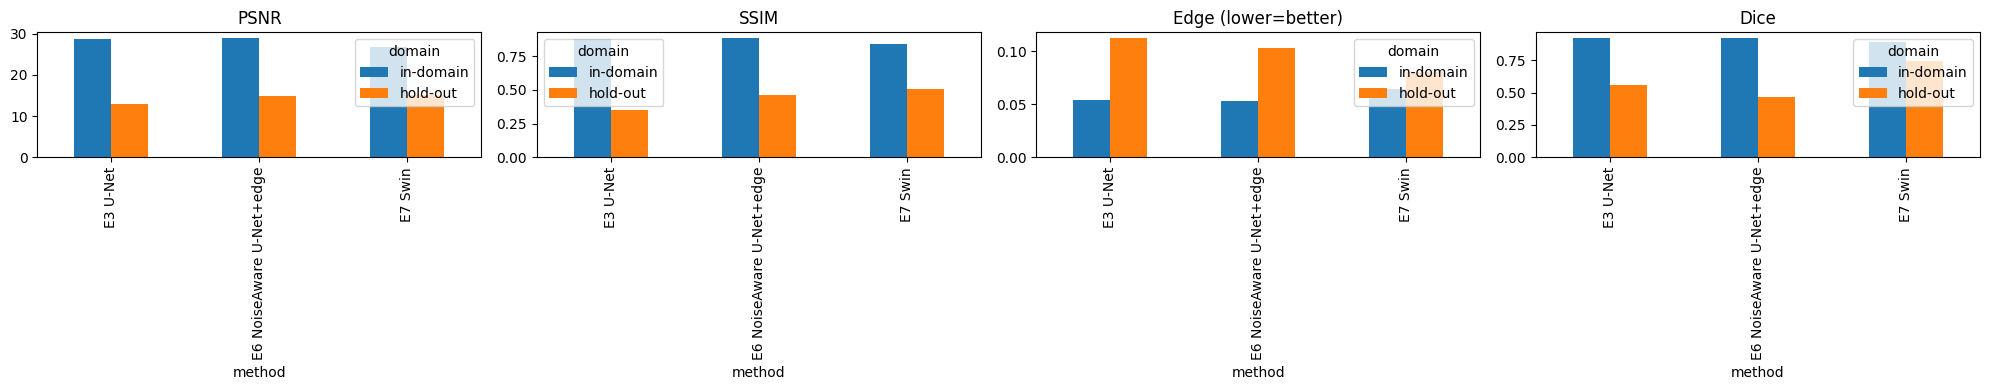


in-domain: difference vs E3 U-Net
                           PSNR   SSIM   Edge   Dice
method                                              
E3 U-Net                  0.000  0.000  0.000  0.000
E6 NoiseAware U-Net+edge  0.100  0.002 -0.001  0.001
E7 Swin                  -2.077 -0.042  0.010 -0.031

hold-out: difference vs E3 U-Net
                           PSNR   SSIM   Edge   Dice
method                                              
E3 U-Net                  0.000  0.000  0.000  0.000
E6 NoiseAware U-Net+edge  1.787  0.107 -0.010 -0.092
E7 Swin                   1.969  0.155 -0.032  0.186


In [21]:
R = pd.DataFrame(res); R.to_csv(WORK / 'results_all_runs.csv', index=False)   # works with partial results too
cols = ['PSNR', 'SSIM', 'Edge', 'Dice']
tab = R.groupby(['domain', 'method'], sort=False)[cols].agg(['mean', 'std']).round(3)
display(tab)   # mean / std over folds (and seeds)
tab.to_csv(WORK / 'results_summary.csv')
print('PSNR per fold:'); display(R.pivot_table(index=['domain', 'method'], columns='fold', values='PSNR', sort=False).round(2))
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, c in zip(ax, cols):
    R.pivot_table(index='method', columns='domain', values=c, sort=False).plot.bar(ax=a, title=c + (' (lower=better)' if c == 'Edge' else ''))
plt.tight_layout(); plt.show()

mean = R.groupby(['domain', 'method'], sort=False)[cols].mean()   # change vs E3 U-Net (answers RQ1-RQ3)
for d in TEST:
    if 'E3 U-Net' in mean.loc[d].index: print(f'\n{d}: difference vs E3 U-Net'); print((mean.loc[d] - mean.loc[d].loc['E3 U-Net']).round(3))

fold 0: train 1475 val 163 test 819 | hold-out noise z-score mean [6.2 3.6] (clipped to +-3)


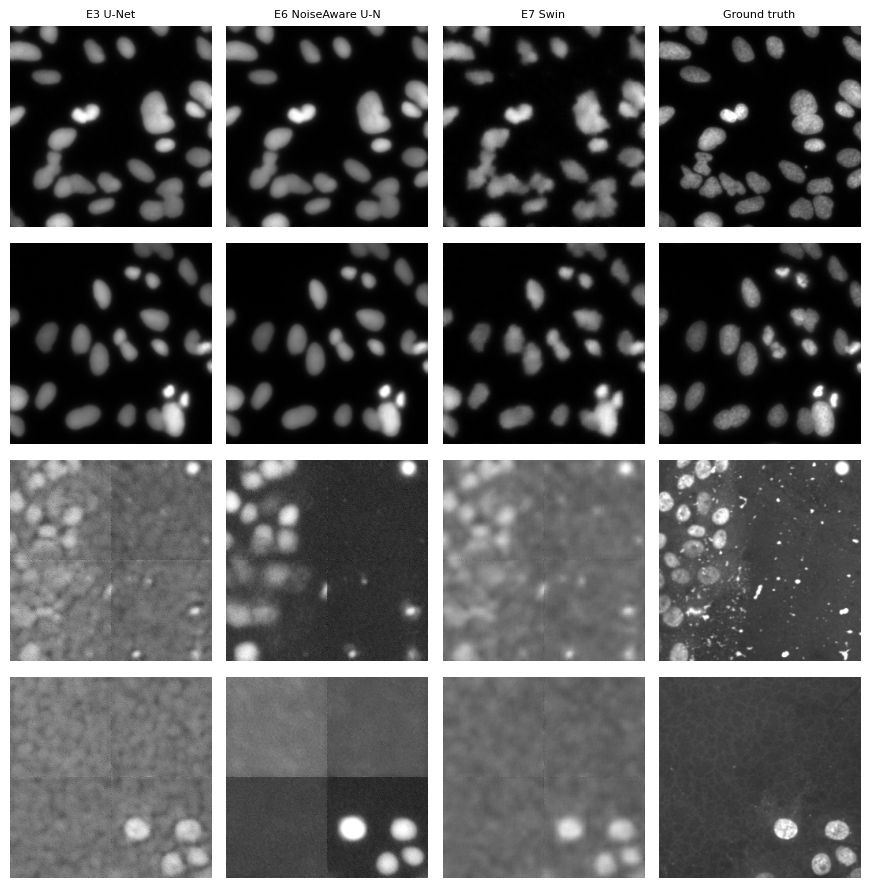

In [22]:
# side-by-side pictures (first 2 images per test set; hold-out shown as a 256x256 centre crop)
set_fold(0)   # pictures come from fold 0, so use fold 0's ground truth
names = ['E1 Noisy', 'E2a Gaussian', 'E2b Median'] + list(EXPS); names = [n for n in names if n in VIS['hold-out']]   # skip runs not finished yet
fig, ax = plt.subplots(4, len(names) + 1, figsize=(2.2 * (len(names) + 1), 9))
for r, (dom, i) in enumerate([(d, i) for d in TEST for i in (0, 1)]):
    sl = (slice(384, 640),) * 2 if dom == 'hold-out' else (slice(None),) * 2
    for c, n in enumerate(names + ['Ground truth']):
        img = TEST[dom][2][i] if n == 'Ground truth' else VIS[dom][n][i]
        ax[r, c].imshow(img[sl], cmap='gray', vmin=0, vmax=1); ax[r, c].axis('off')
        if r == 0: ax[r, c].set_title(n.split(' ')[0] + ' ' + ' '.join(n.split(' ')[1:])[:14], fontsize=8)
    ax[r, 0].set_ylabel(dom)
plt.tight_layout(); plt.show()

## 8. How to read the results
- **RQ1** (noise-aware helps on unseen condition?): compare E5 vs E3 in the *hold-out* rows.
- **RQ2** (edge loss keeps borders without hurting PSNR/SSIM?): compare E4 vs E3 on *Edge*, *Dice*, *PSNR*, *SSIM*.
- **RQ3** (both together?): E6 vs E3/E4/E5. Swin: E7 vs E3 and E8 vs E6.
- The std in the table is across the 3 CV folds. Differences smaller than that std are **not** evidence of an effect; report them honestly either way. For a paired view use the per-fold PSNR table (same folds for every method).

**Notes:** the hold-out noise-feature z-scores printed in section 2 show how far `large` is from the training noise range (conditioning values are clipped to ±3, so FiLM can only partly adapt there). Large images are denoised as overlapping 256×256 tiles (stride 128, averaged). Set `QUICK=True` for a quick smoke test, and CV already means 3 training runs per experiment (add seeds via `SEEDS` only if you have time); Swin is the slowest part (full-resolution attention).

## 9. Backup (for interactive sessions)
Zips all checkpoints; download `ckpt_backup.zip` from the Output panel to continue later.

In [23]:
shutil.make_archive(str(WORK / 'ckpt_backup'), 'zip', CK); print('ckpt_backup.zip:', round((WORK / 'ckpt_backup.zip').stat().st_size / 1e6, 1), 'MB')

ckpt_backup.zip: 96.4 MB
